# A股小市值策略：结果复算与证据边界

本Notebook仅使用公开结果表，从头复算选组、绩效、HAC区间及敏感性图表。**它不是从原始行情重新生成交易账本。**

2015—2023年五档参与选优，单边30bp成本后月收益夏普决定赢家；2024—2025年用于固定赢家的历史留出评价。这段历史已在研究迭代中查看，不能称为未窥视验证。完整数据核验见 `full_reproduction.ipynb` 和 `RUN_GUIDE.md`。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Image
root = Path.cwd()
assert (root/'config.json').exists(), '请在项目根目录启动Notebook'
config = json.loads((root/'config.json').read_text())
frozen = json.loads((root/'results/selection.json').read_text())
monthly = pd.read_csv(root/'results/monthly.csv', float_precision='round_trip')
primary = monthly[monthly.cost_bps.eq(30)].copy()
bands = config['candidates']
labels = {s: f"{config['buckets'][s][0]}–{config['buckets'][s][1]}" for s in bands}
wide = primary.pivot(index='return_month', columns='strategy', values='net_return').sort_index()
assert not wide.isna().any().any()
assert list(wide.index) == list(pd.period_range('2015-01','2025-12',freq='M').astype(str))
print('132个月；5档策略＋中证1000；已包含策略成本，不能再重复扣减。')

132个月；5档策略＋中证1000；已包含策略成本，不能再重复扣减。


## 1. 只用样本内数据选赢家

夏普＝√12×月收益均值÷月收益样本标准差；无风险率为0。完全并列先比较低换手，再比较较大的名次区间。复合年化收益不参与选组。

In [2]:
train = primary[primary.return_month.between('2015-01','2023-12') & primary.strategy.isin(bands)]
rows = []
for band,g in train.groupby('strategy'):
    assert len(g)==108 and g.status.eq('ok').all()
    r=g.net_return
    rows.append(dict(strategy=band, sharpe=np.sqrt(12)*r.mean()/r.std(ddof=1),
                     cagr=np.prod(1+r)**(12/len(r))-1, turnover=g.turnover.mean(),
                     lower=config['buckets'][band][0]))
scores=pd.DataFrame(rows).sort_values(['sharpe','turnover','lower'],ascending=[False,True,False])
winner=scores.iloc[0].strategy
assert winner == frozen['winner']
for row in scores.itertuples():
    assert np.isclose(row.sharpe, frozen['scores'][row.strategy]['score'])
display(scores)
print('冻结赢家：',labels[winner])

,strategy,sharpe,cagr,turnover,lower
0,R001_100,0.880041,0.229942,0.379053,1
1,R101_200,0.682958,0.157272,0.735343,101
2,R201_300,0.570412,0.121629,0.925973,201
4,R401_500,0.362545,0.062703,1.071556,401
3,R301_400,0.331844,0.054697,1.013420,301


冻结赢家： 1–100


## 2. 固定赢家后评价历史留出期

各期净值从1归一化；2024年策略收益承接原持仓，并非重新从现金开户。指数是价格收益，策略是成本后复权收益，两者不等同于可交易的净超额收益。

,period,strategy,n,cagr,sharpe,monthly_max_drawdown,worst_month
0,TRAIN,R001_100,108,0.229942,0.880041,-0.429646,-0.222836
1,TRAIN,R101_200,108,0.157272,0.682958,-0.435922,-0.211869
2,TRAIN,R201_300,108,0.121629,0.570412,-0.479609,-0.194673
3,TRAIN,R301_400,108,0.054697,0.331844,-0.511470,-0.214369
4,TRAIN,R401_500,108,0.062703,0.362545,-0.499361,-0.192157
5,TRAIN,CSI1000,108,-0.002613,0.133982,-0.665643,-0.304174
6,TEST,R001_100,24,0.234212,0.784065,-0.335258,-0.186548
7,TEST,R101_200,24,0.184501,0.714255,-0.301593,-0.202258
8,TEST,R201_300,24,0.185191,0.749502,-0.313963,-0.184685
9,TEST,R301_400,24,0.145589,0.637899,-0.306026,-0.193055


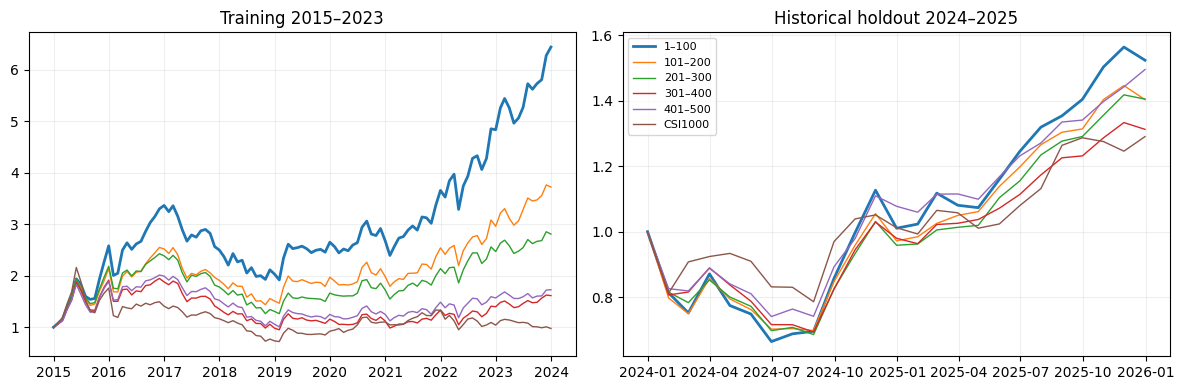

In [3]:
summary=[]
for period,start,end in [('TRAIN','2015-01','2023-12'),('TEST','2024-01','2025-12')]:
    for band in bands+['CSI1000']:
        r=wide.loc[start:end,band]
        nav=np.r_[1,np.cumprod(1+r)]
        summary.append(dict(period=period,strategy=band,n=len(r),cagr=np.prod(1+r)**(12/len(r))-1,
            sharpe=np.sqrt(12)*r.mean()/r.std(ddof=1),
            monthly_max_drawdown=np.min(nav/np.maximum.accumulate(nav)-1),worst_month=r.min()))
summary=pd.DataFrame(summary)
display(summary)
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,start,end,title in zip(axes,['2015-01','2024-01'],['2023-12','2025-12'],['Training 2015–2023','Historical holdout 2024–2025']):
    for band in bands+['CSI1000']:
        r=wide.loc[start:end,band]
        dates=pd.period_range(pd.Period(start,'M')-1,end,freq='M').to_timestamp('M')
        ax.plot(dates,np.r_[1,np.cumprod(1+r)],label=labels.get(band,band),linewidth=2 if band==winner else 1)
    ax.set_title(title);ax.grid(alpha=.2)
axes[1].legend(fontsize=8);plt.tight_layout();plt.show()

## 3. 复算相对中证1000的HAC(6)区间

检验对象是**平均月收益差**，不是CAGR之差。HAC容许异方差和至多6阶的自相关修正；沿用小样本校正与正态近似95%区间。包含0意味着当前样本无法排除零均值差，不等于证明没有差异。

In [4]:
spread=wide.loc['2024-01':'2025-12',winner]-wide.loc['2024-01':'2025-12','CSI1000']
assert len(spread)==24 and spread.notna().all()
fit=sm.OLS(spread.to_numpy(),np.ones((len(spread),1))).fit(
    cov_type='HAC',cov_kwds={'maxlags':6,'use_correction':True})
mu,se=float(fit.params[0]),float(fit.bse[0])
ci=(mu-1.96*se,mu+1.96*se)
published=json.loads((root/'results/paired_tests.json').read_text())['comparisons']
record=next(x for x in published if x['strategy']==winner and x['comparator']=='CSI1000' and x['period']=='TEST')
np.testing.assert_allclose([mu,se,*ci],[record['mean'],record['hac_se'],record['ci95_low'],record['ci95_high']],atol=1e-12)
display(pd.DataFrame([{'月均差_pp':mu*100,'HAC标准误_pp':se*100,'区间下限_pp':ci[0]*100,'区间上限_pp':ci[1]*100}]))

,月均差_pp,HAC标准误_pp,区间下限_pp,区间上限_pp
0,0.864154,1.181658,-1.451897,3.180204


## 4. 风险、ST规则及控制回归

日度最大回撤与前面的月度回撤是不同指标。风险退出受停牌和跌停限制；本模型成交卖款最早次交易日补仓。控制回归是毛收益描述，不能称为成本后Alpha。

R001_100 日度最大回撤 -45.16%
CSI1000 日度最大回撤 -27.08%


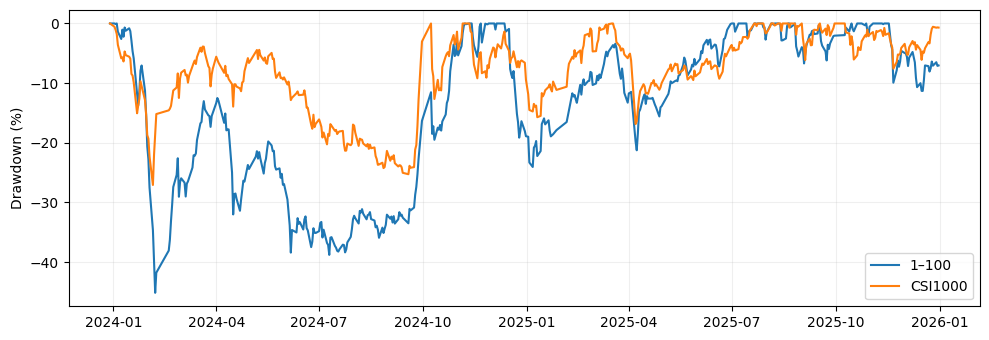

,strategy,cost_bps,period,n_expected,n_valid,complete,mean,monthly_std,cagr,annualized_mean,...,recovery_date,recovery_sessions,drawdown_unrecovered,n_daily,mean_cash,max_cash,mean_holdings,min_holdings,max_holdings,rule
1,R001_100,30,TEST,24,24,True,0.022465,0.098472,0.236719,0.269585,...,2024-11-07,201.0,False,485,0.012297,0.296750,99.657732,72.0,105.0,FILTER_ONLY
15,R101_200,30,TEST,24,24,True,0.017844,0.086234,0.185378,0.214123,...,2024-11-07,201.0,False,485,0.022905,0.497504,98.800000,52.0,102.0,FILTER_ONLY
29,R201_300,30,TEST,24,24,True,0.017384,0.080148,0.185798,0.208614,...,2024-11-28,216.0,False,485,0.027327,0.586481,98.659794,45.0,103.0,FILTER_ONLY
43,R301_400,30,TEST,24,24,True,0.014285,0.077735,0.145221,0.171423,...,2024-11-11,203.0,False,485,0.030955,0.616895,98.484536,40.0,105.0,FILTER_ONLY
57,R401_500,30,TEST,24,24,True,0.019580,0.074794,0.222974,0.234964,...,2024-11-05,199.0,False,485,0.033783,0.654305,98.098969,38.0,101.0,FILTER_ONLY
71,R001_100,30,TEST,24,24,True,0.022247,0.098513,0.233495,0.266958,...,2024-11-07,201.0,False,485,0.014735,0.296750,99.668041,74.0,107.0,EXIT_CASH
85,R101_200,30,TEST,24,24,True,0.017772,0.086217,0.184391,0.213259,...,2024-11-07,201.0,False,485,0.024358,0.497504,98.927835,52.0,102.0,EXIT_CASH
99,R201_300,30,TEST,24,24,True,0.017385,0.080111,0.185843,0.208619,...,2024-11-28,216.0,False,485,0.028184,0.586481,98.849485,45.0,103.0,EXIT_CASH
113,R301_400,30,TEST,24,24,True,0.014292,0.077722,0.145322,0.171499,...,2024-11-11,203.0,False,485,0.032373,0.616895,98.958763,40.0,105.0,EXIT_CASH
127,R401_500,30,TEST,24,24,True,0.019498,0.074671,0.221893,0.233975,...,2024-11-05,199.0,False,485,0.034594,0.654305,98.540206,38.0,101.0,EXIT_CASH


,period,model,term,n_expected,n_valid,complete,mean,hac_lags,hac_se,ci95_low,ci95_high,t_stat,inference_status
11,TEST,baseline,R101_200,24,24,True,-0.005302,6,0.004214,-0.013561,0.002957,-1.258328,ok
12,TEST,baseline,R201_300,24,24,True,-0.006058,6,0.004940,-0.015741,0.003625,-1.226211,ok
13,TEST,baseline,R301_400,24,24,True,-0.006682,6,0.005170,-0.016815,0.003451,-1.292461,ok
14,TEST,baseline,R401_500,24,24,True,-0.002842,6,0.006972,-0.016508,0.010824,-0.407629,ok
15,TEST,full,R101_200,24,24,True,-0.004980,6,0.003840,-0.012506,0.002547,-1.296834,ok
16,TEST,full,R201_300,24,24,True,-0.005007,6,0.004664,-0.014149,0.004135,-1.073510,ok
17,TEST,full,R301_400,24,24,True,-0.002923,6,0.004157,-0.011070,0.005225,-0.703054,ok
18,TEST,full,R401_500,24,24,True,-0.001849,6,0.006027,-0.013662,0.009965,-0.306747,ok
19,TEST,full,log_adv20,24,24,True,-0.003196,6,0.003033,-0.009141,0.002749,-1.053631,ok
20,TEST,full,return_prev1m,24,24,True,-0.047844,6,0.037424,-0.121196,0.025508,-1.278426,ok


,return_month,bucket,n_ranked,n_complete,coverage,n_model_obs,baseline_status,full_status,n_full_parameters,log_adv20_p01,log_adv20_p99,return_prev1m_p01,return_prev1m_p99
0,2015-01,R001_100,100,86,0.86,446,ok,ok,60,16.630232,19.172313,-0.308882,0.143816
1,2015-01,R101_200,100,87,0.87,446,ok,ok,60,16.630232,19.172313,-0.308882,0.143816
2,2015-01,R201_300,100,90,0.90,446,ok,ok,60,16.630232,19.172313,-0.308882,0.143816
3,2015-01,R301_400,100,89,0.89,446,ok,ok,60,16.630232,19.172313,-0.308882,0.143816
4,2015-01,R401_500,100,94,0.94,446,ok,ok,60,16.630232,19.172313,-0.308882,0.143816


In [5]:
daily=pd.read_csv(root/'results/daily_nav.csv')
daily['date']=pd.to_datetime(daily.date,format='mixed')
fig,ax=plt.subplots(figsize=(10,3.5))
for band in [winner,'CSI1000']:
    g=daily[daily.strategy.eq(band)].sort_values('date')
    prior=g[g.date<'2024-01-01'].iloc[-1]
    test=g[g.date>='2024-01-01']
    nav=np.r_[prior.nav,test.nav]
    dd=nav/np.maximum.accumulate(nav)-1
    ax.plot([prior.date,*test.date],100*dd,label=labels.get(band,band))
    print(band,'日度最大回撤',f'{dd.min():.2%}')
ax.set_ylabel('Drawdown (%)');ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()
display(pd.read_csv(root/'results/st_ablation_performance.csv').query("period=='TEST'"))
display(pd.read_csv(root/'results/regression_summary.csv').query("period=='TEST'"))
display(pd.read_csv(root/'results/regression_coverage.csv').head())

## 5. 扩展区间与执行敏感性

501—1000名是事后描述，未参与五档选优。资金实验在2024年初从现金建立新账户，应与同起点连续份额22.88%年化比较，不能直接减去主策略承接旧持仓的23.42%。

,strategy,period,cagr,sharpe,daily_max_drawdown
0,R501_600,TRAIN,0.039390,0.275419,-0.605241
1,R501_600,TEST,0.141662,0.609768,-0.381247
2,R501_600,ALL,0.057278,0.340978,-0.605241
3,R501_600,2015,0.845754,1.668291,-0.444481
4,R501_600,2016,-0.024676,0.061169,-0.228855
...,...,...,...,...,...
65,R901_1000,2021,0.074517,0.506824,-0.143395
66,R901_1000,2022,-0.058909,-0.063684,-0.242243
67,R901_1000,2023,0.012426,0.156804,-0.141066
68,R901_1000,2024,-0.080999,-0.056471,-0.365437


,mode,initial_capital,cagr,sharpe,mean_cash,mean_holdings
15,CONTINUOUS,1,0.228817,0.768560,0.012221,100.043299
16,LOT,100000,0.192132,0.975886,0.450188,67.542268
17,LOT_MIN5,100000,0.171718,0.898467,0.455754,66.610309
18,LOT,200000,0.224741,0.878914,0.208826,96.651546
19,LOT_MIN5,200000,0.197304,0.802067,0.221511,95.193814
20,LOT,300000,0.227243,0.840218,0.145022,99.769072
21,LOT_MIN5,300000,0.213499,0.803235,0.147944,99.758763
22,LOT,500000,0.222184,0.792325,0.093500,100.189691
23,LOT_MIN5,500000,0.212066,0.767214,0.093842,100.179381
24,LOT,1000000,0.227907,0.783354,0.050177,100.232990


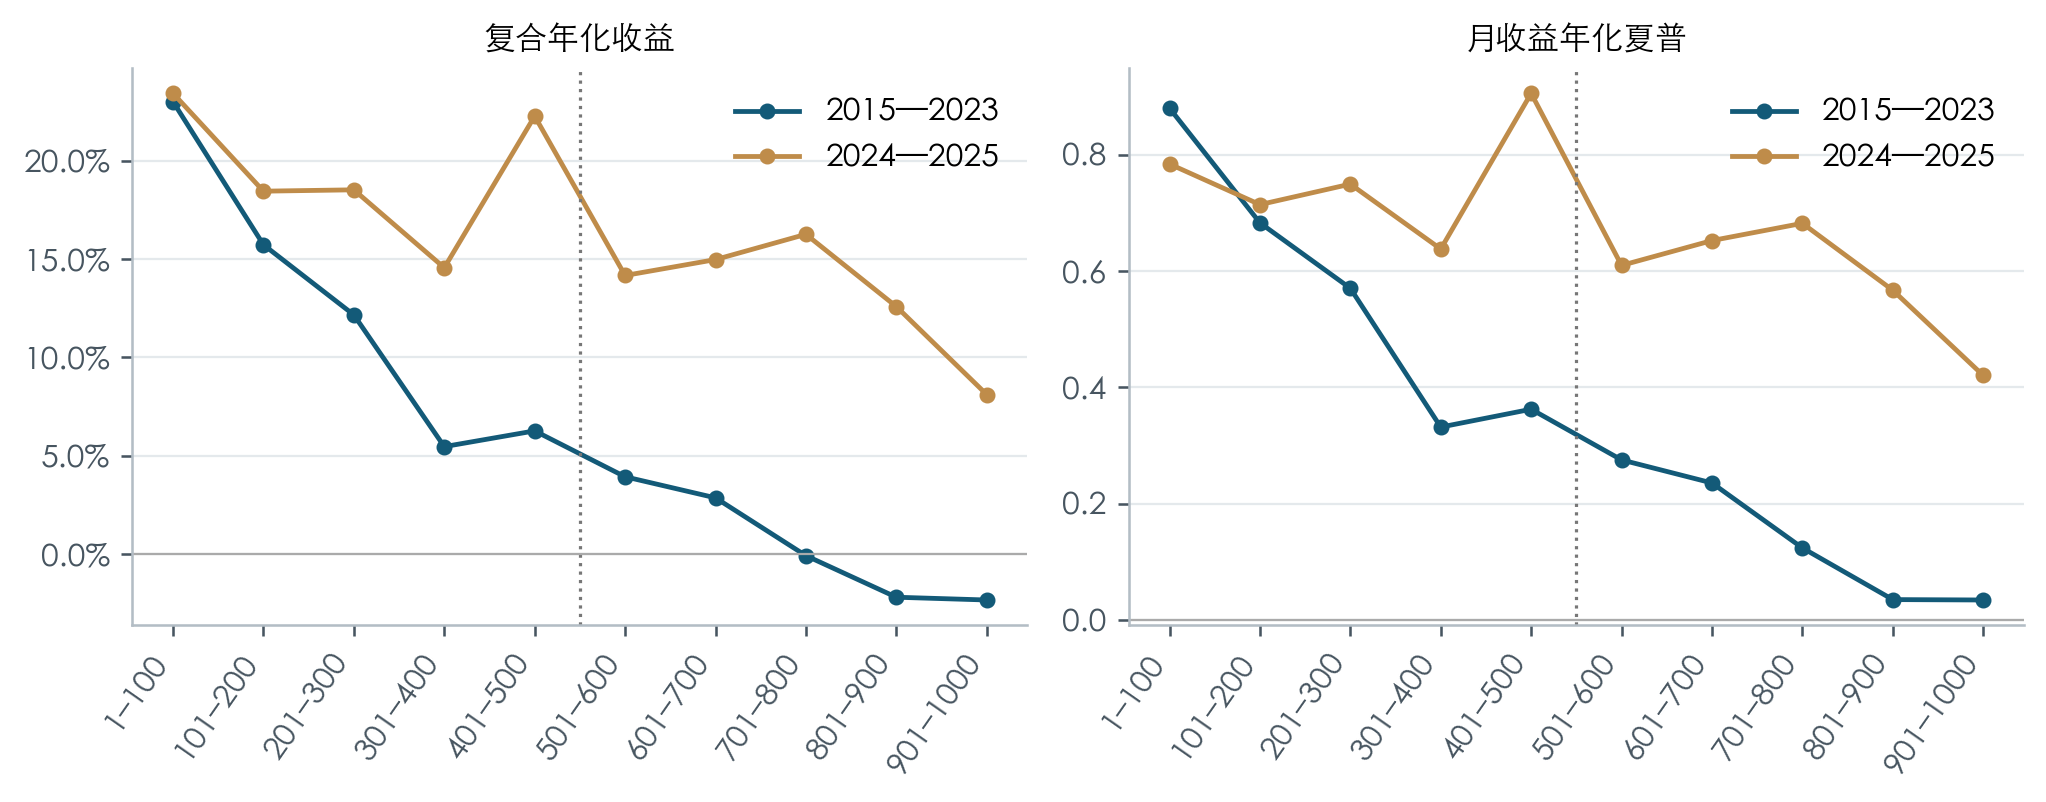

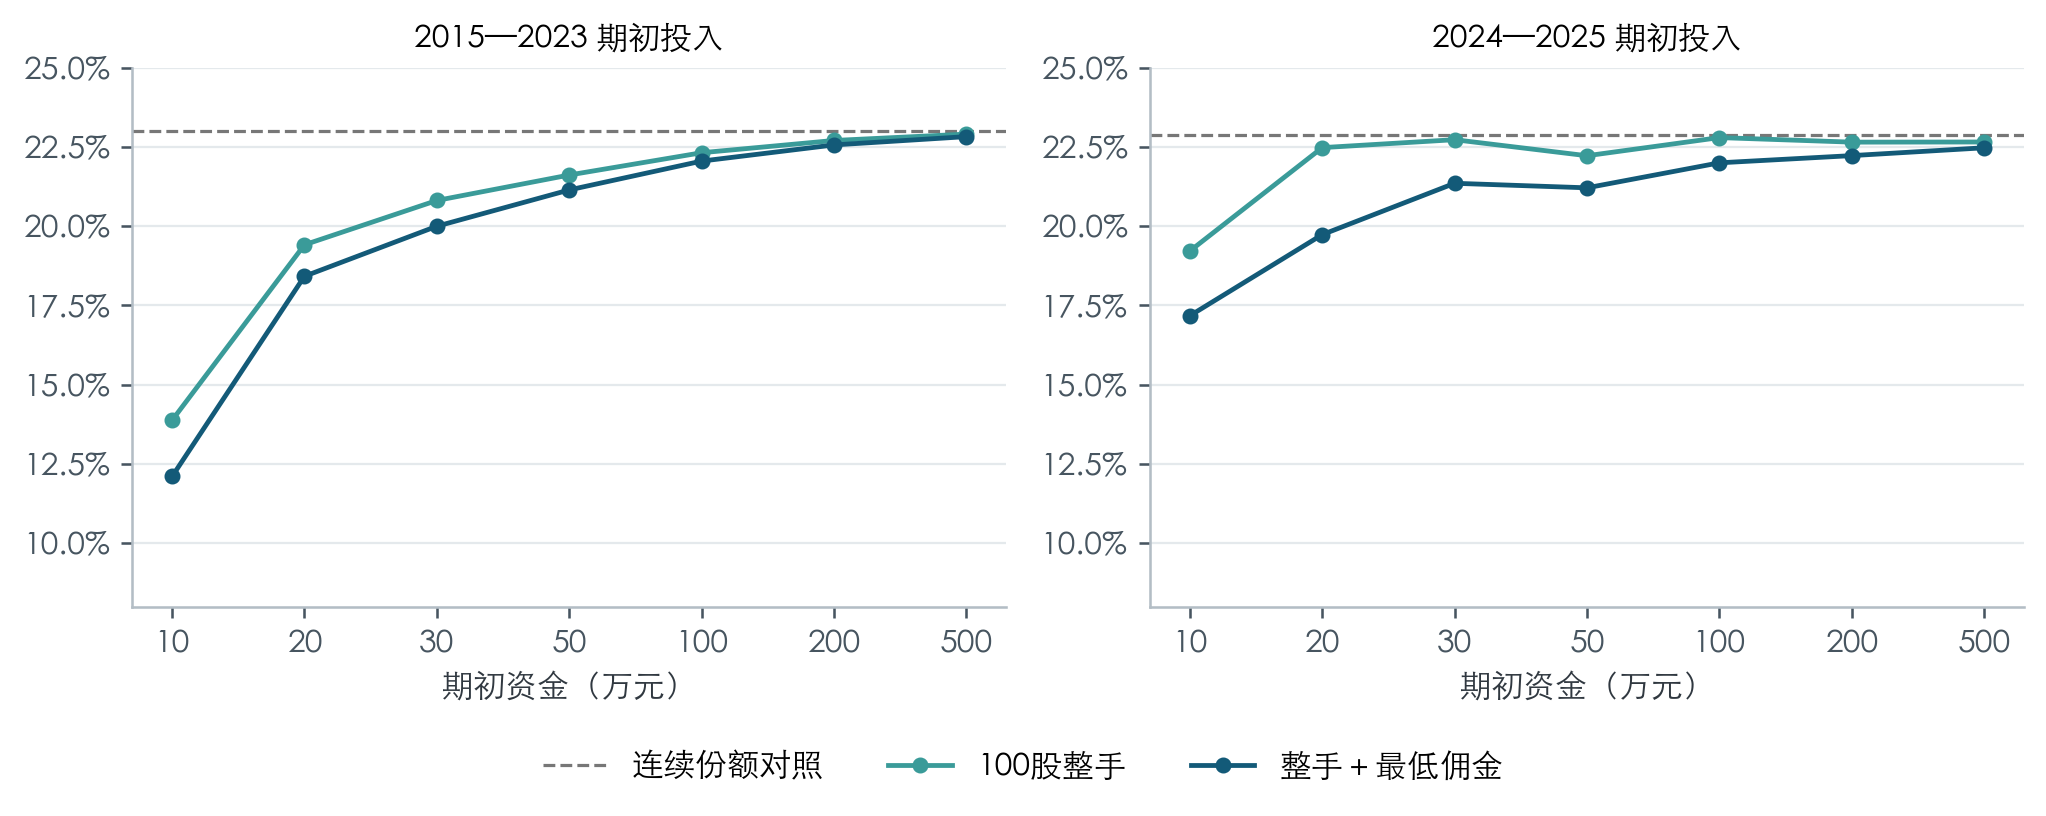

,strategy,cost_bps,period,n_expected,n_valid,complete,mean,monthly_std,cagr,annualized_mean,...,drawdown_trough,recovery_date,recovery_sessions,drawdown_unrecovered,n_daily,mean_cash,max_cash,mean_holdings,min_holdings,max_holdings
1,R001_100,10,TEST,24,24,True,0.023071,0.098536,0.245557,0.276853,...,2024-02-07,2024-11-06,200.0,False,485,0.012608,0.297235,100.018557,75.0,107.0
4,R001_100,30,TEST,24,24,True,0.022295,0.098502,0.234212,0.267540,...,2024-02-07,2024-11-07,201.0,False,485,0.012411,0.296750,100.018557,74.0,107.0
7,R001_100,50,TEST,24,24,True,0.021521,0.098469,0.222987,0.258249,...,2024-02-07,2024-11-07,201.0,False,485,0.012228,0.296265,100.018557,75.0,107.0


In [6]:
extended=pd.read_csv(root/'results/supplement/extended_monthly.csv')
ext_performance=pd.read_csv(root/'results/supplement/extended_performance.csv')
display(ext_performance[['strategy','period','cagr','sharpe','daily_max_drawdown']])
capital=pd.read_csv(root/'results/supplement/capital_performance.csv')
display(capital.query("period=='TEST'")[['mode','initial_capital','cagr','sharpe','mean_cash','mean_holdings']])
for figure in ['extended_bands','capital_sensitivity']:
    display(Image(filename=str(root/'results/word_figures'/f'{figure}.png')))
display(pd.read_csv(root/'results/cost_sensitivity.csv').query("strategy==@winner and period=='TEST'"))

## 6. 成交容量与额外市场冲击

这一层固定原赢家，分别在2015—2023和2024—2025从现金开户，8个本金×8个情景×2个时期共128格。收益随资金复利累积，所以同时看**期初本金、实际最高净值、现金与未成交**。主回测仍沿用原持仓路径，不与现金开户情景混减。

- `OPEN_BASE`：原开盘、整手和最低佣金对照。
- `VWAP_BASE`：全天成交均价代理、无容量限制。包含更严格的当日交易资格，差额并非纯价格效应。
- `CAP_1P`：加1%容量；`CAP_1P_SIGMA`再要求已知历史波动率，仍无额外冲击。
- `MAIN_1P`：相同波动率覆盖条件下，加入η=0.5的额外冲击；另有0.5%／5%参与率及η=1的敏感性。

股票每日买卖共用额度为 `min(p × lag_ADV20, p × 当日成交额)`。计划量只使用前收资料；当日成交量只决定模拟成交。额外费用为 `C(Q)=ησQ√(Q/ADV)` 的累计增量，在原30bp基础上扣一次，不再重复改变成交价。η未经真实订单校准。

缺失流动性不填0；部分成交继续尝试，ST分批卖出仍只补同一个替代仓位，每笔卖款最早次日使用。这里是日频压力情景，未模拟竞价或盘中队列。

,initial_capital,max_nav_yuan,cagr,sharpe,daily_max_drawdown,mean_cash,attempt_completion,impact_bps_per_traded_yuan,final_pending_risk_stocks
4,100000,1.436071e+05,0.175140,0.920219,-0.216984,0.454643,0.809534,0.634661,0
12,300000,4.698647e+05,0.212019,0.802105,-0.372952,0.148739,0.840049,0.951814,0
20,1000000,1.591578e+06,0.217728,0.759764,-0.428989,0.051362,0.858201,1.738039,0
28,2000000,3.201553e+06,0.220834,0.756946,-0.441003,0.029956,0.863991,2.490702,0
36,5000000,8.042338e+06,0.223296,0.757933,-0.447486,0.018745,0.870106,3.972679,0
44,10000000,1.617445e+07,0.226580,0.763956,-0.449428,0.015193,0.872767,5.618527,0
52,30000000,4.887566e+07,0.230920,0.774051,-0.450368,0.013502,0.848951,9.372484,0
60,50000000,8.182717e+07,0.233791,0.782262,-0.448543,0.014510,0.779274,11.007444,0


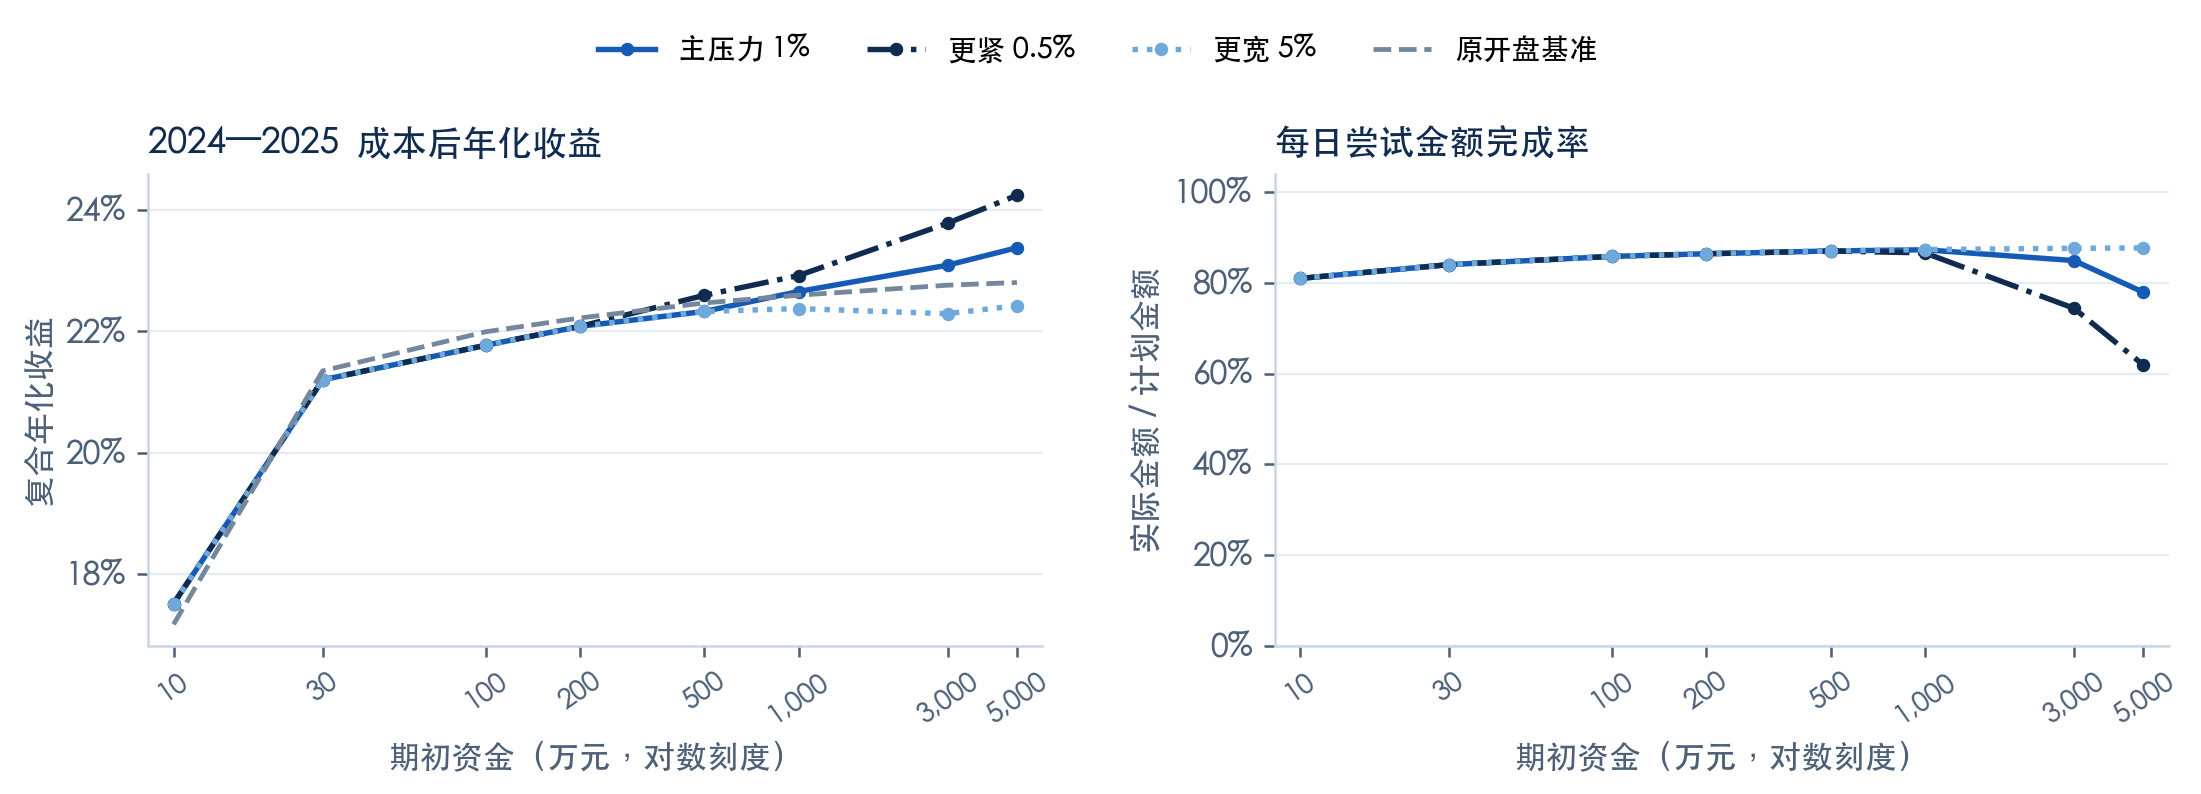

In [7]:
caproot=root/'results/capacity'
protocol=json.loads((caproot/'protocol.json').read_text())
cap_month=pd.read_csv(caproot/'monthly.csv')
cap_day=pd.read_csv(caproot/'daily.csv.gz')
cap_saved=pd.read_csv(caproot/'performance.csv')
keys=['period','scenario','initial_capital']
expected={(p,s,c) for p in protocol['periods'] for s in protocol['scenarios'] for c in protocol['capitals_yuan']}
assert set(map(tuple,cap_saved[keys].to_numpy())) == expected
cap_rows=[]
for key,g in cap_month.groupby(keys):
    period,scenario,initial_capital=key
    g=g.sort_values('return_month')
    assert g.return_month.tolist()==pd.period_range(*protocol['periods'][period],freq='M').astype(str).tolist()
    r=g.net_return.to_numpy()
    d=cap_day[(cap_day.period==period)&(cap_day.scenario==scenario)&(cap_day.initial_capital==initial_capital)].sort_values('date')
    nav=np.r_[initial_capital,d.nav.to_numpy()]
    cap_rows.append(dict(zip(keys,key))|dict(cagr=np.prod(1+r)**(12/len(r))-1,
        sharpe=np.sqrt(12)*r.mean()/r.std(ddof=1),
        daily_max_drawdown=(nav/np.maximum.accumulate(nav)-1).min(),
        mean_cash=d.cash_weight.mean(),max_nav_yuan=nav.max()))
cap_recalc=pd.DataFrame(cap_rows)
cap_check=cap_recalc.merge(cap_saved,on=keys,suffixes=('_new','_saved'),validate='one_to_one')
for metric in ['cagr','sharpe','daily_max_drawdown','mean_cash','max_nav_yuan']:
    np.testing.assert_allclose(cap_check[metric+'_new'],cap_check[metric+'_saved'],rtol=1e-9,atol=1e-10)
show=cap_saved.query("period=='TEST' and scenario=='MAIN_1P'").sort_values('initial_capital')
display(show[['initial_capital','max_nav_yuan','cagr','sharpe','daily_max_drawdown','mean_cash',
              'attempt_completion','impact_bps_per_traded_yuan','final_pending_risk_stocks']])
display(Image(filename=str(root/'results/word_figures/capacity_stress.png')))

### 容量如何传导到收益，哪些指标不能混用

下面复算逐日委托尝试的金额完成率，并展示四个递进差额。**重试会再次进入分母**，该指标不能理解为“全部原始委托最终完成了多少”。现金率也不等同于未完成率：现金同时受整手、卖款可用时间、风险退出与月度目标影响。

差额比较反映约束、费用和持仓路径共同变化。费用可能使某笔整手买入不再可行，后续持仓因此不同；收益偶尔上升不能反推冲击有益。期末普通目标缺口、替代仓位预算和待退出ST需要单独检查。

,initial_capital,scenario,reference,cagr_difference,mean_cash_difference
0,100000,VWAP_BASE,OPEN_BASE,0.003594,-0.001113
1,100000,CAP_1P,VWAP_BASE,0.000000,0.000000
2,100000,CAP_1P_SIGMA,CAP_1P,0.000000,0.000000
3,100000,MAIN_1P,CAP_1P_SIGMA,-0.000172,0.000002
4,300000,VWAP_BASE,OPEN_BASE,-0.001089,0.000665
5,300000,CAP_1P,VWAP_BASE,0.000000,0.000000
6,300000,CAP_1P_SIGMA,CAP_1P,0.000000,0.000000
7,300000,MAIN_1P,CAP_1P_SIGMA,-0.000391,0.000129
8,1000000,VWAP_BASE,OPEN_BASE,-0.001362,0.001064
9,1000000,CAP_1P,VWAP_BASE,0.000000,0.000000


,initial_capital,month_end_mean_target_shortfall_weight,final_replacement_unfilled_budget,max_risk_sell_delay,final_pending_risk_stocks,final_pending_risk_weight
4,100000,0.456169,0.0,16,0,0.0
12,300000,0.148460,0.0,16,0,0.0
20,1000000,0.052922,0.0,16,0,0.0
28,2000000,0.029684,0.0,16,0,0.0
36,5000000,0.016908,0.0,16,0,0.0
44,10000000,0.012666,0.0,16,0,0.0
52,30000000,0.010065,0.0,16,0,0.0
60,50000000,0.010329,0.0,16,0,0.0


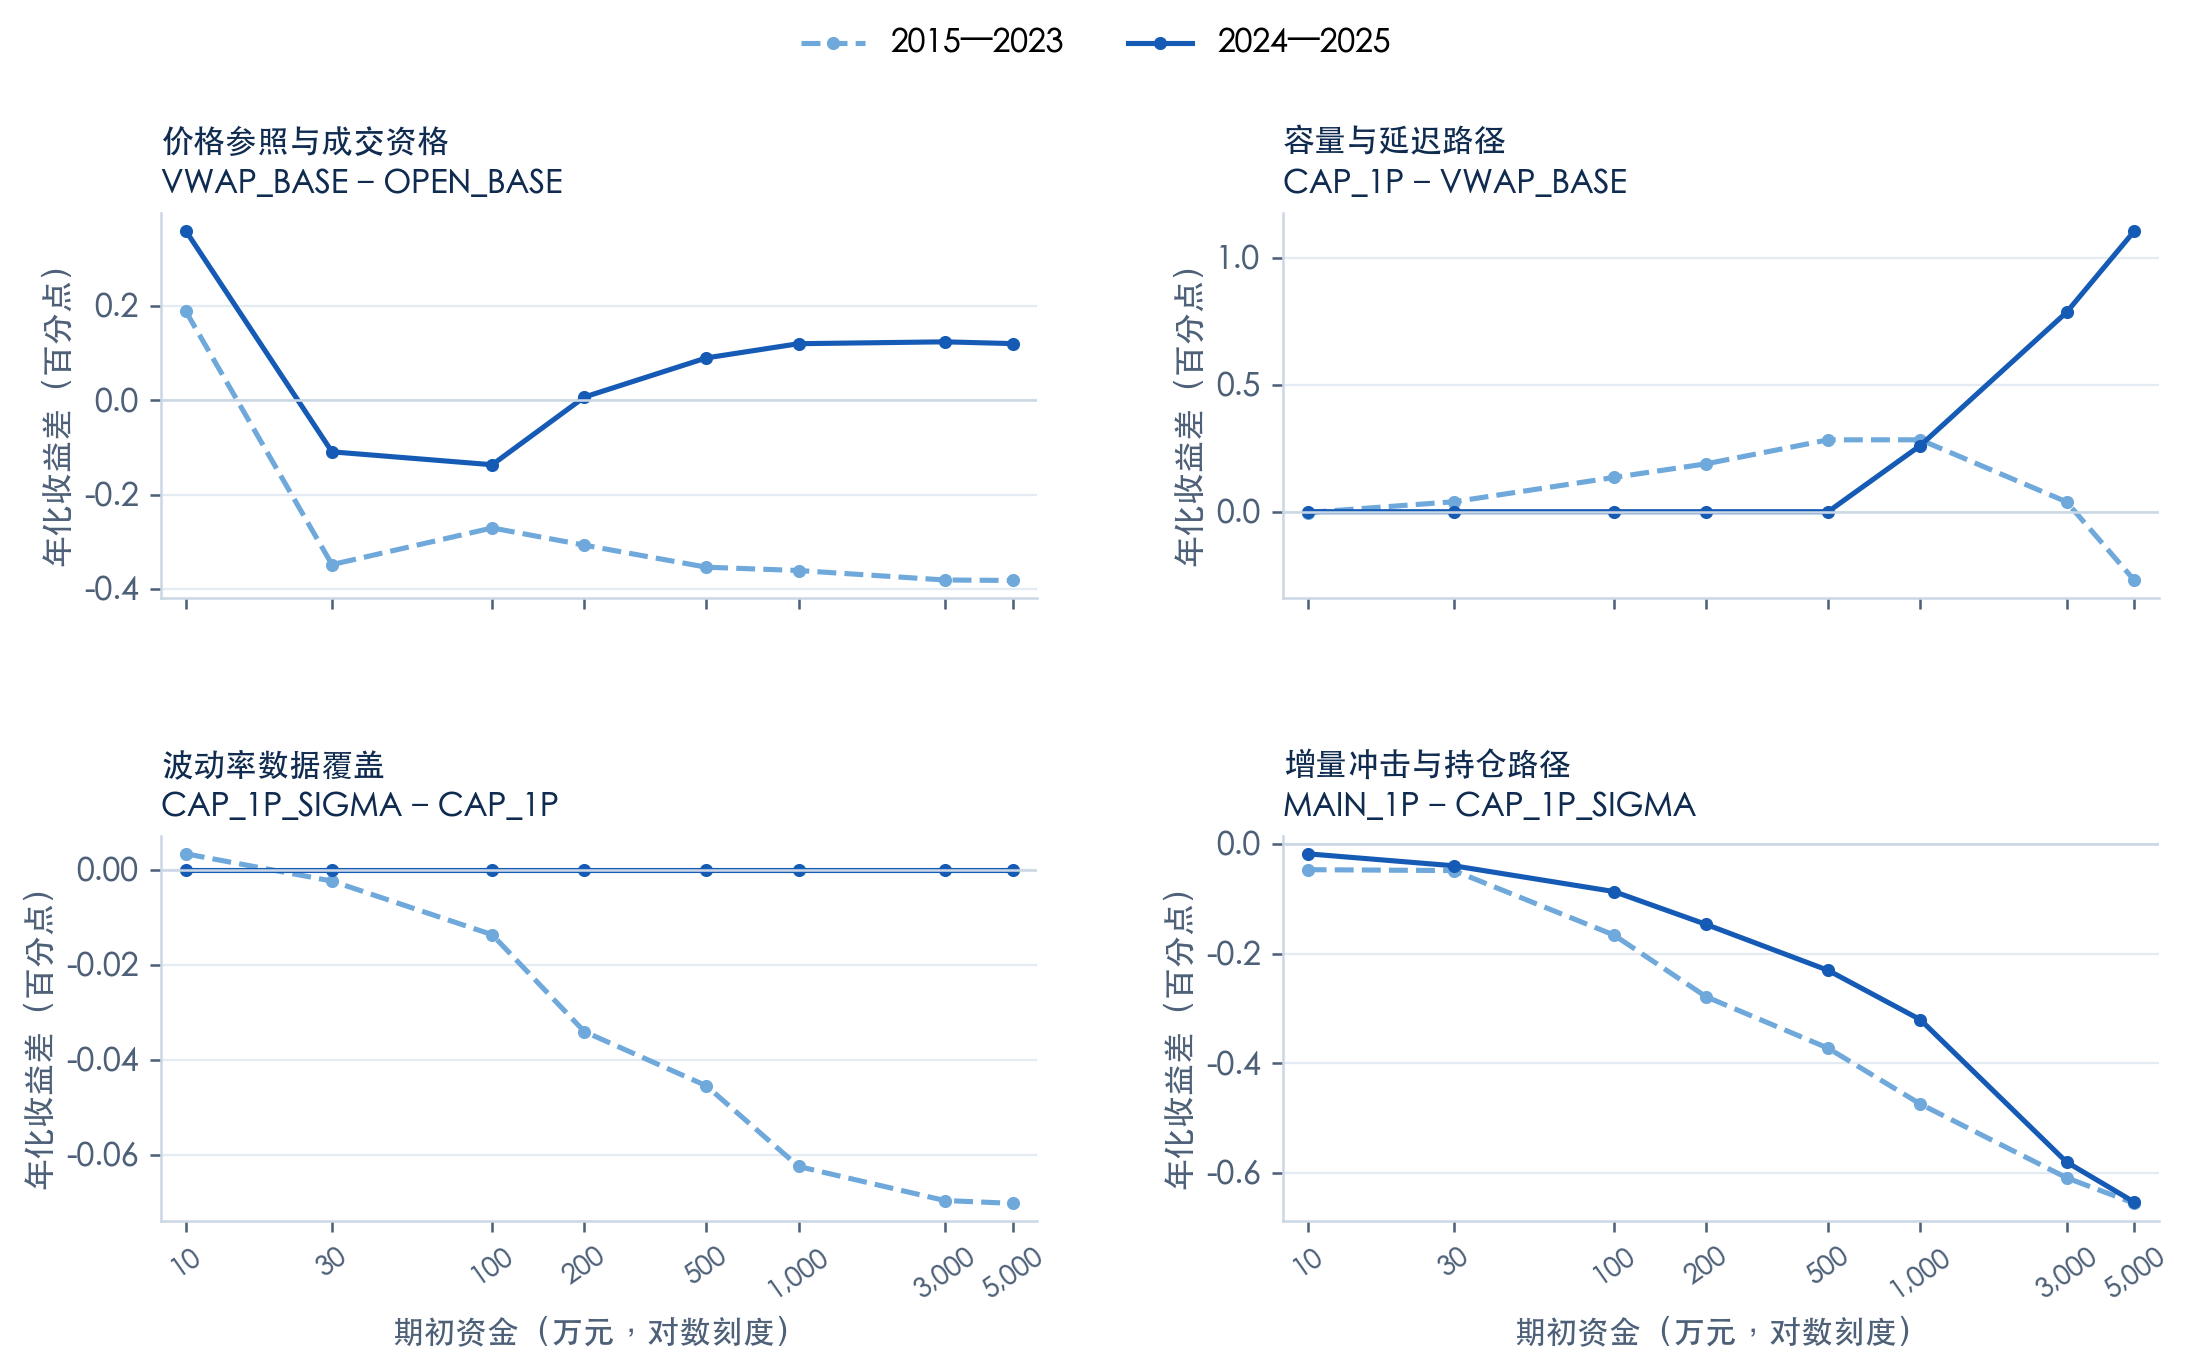

adv_unknown_all                         1418301
adv_zero_all                             142952
known_zero_amount_sessions               230271
missing_volume_on_quoted_market_rows          0
n_dates                                    2756
n_stocks                                   3342
new_daily_rows                          7629139
old_new_differences                           0
sigma_unknown_all                       1427993
unused_provider_preclose_missing_all        230
vwap_anomalies_all                           72
vwap_anomalies_market                         0
Name: input_coverage, dtype: int64

完成率是逐日尝试口径；ST最大延迟仅涵盖已成交部分，仍须检查未退出敞口。


In [8]:
attempt=pd.read_csv(caproot/'attempt_summary.csv')
all_attempts=attempt.query("side=='all' and order_reason=='all'")
np.testing.assert_allclose(all_attempts.attempt_filled_value/all_attempts.attempt_requested_value,
                           all_attempts.attempt_completion,atol=1e-12)
deltas=pd.read_csv(caproot/'performance_differences.csv')
lookup=cap_saved.set_index(keys)
for row in deltas.itertuples():
    current=lookup.loc[(row.period,row.scenario,row.initial_capital)]
    previous=lookup.loc[(row.period,row.reference,row.initial_capital)]
    for metric in ['cagr','sharpe','daily_max_drawdown','mean_cash','attempt_completion']:
        assert np.isclose(current[metric]-previous[metric],getattr(row,metric+'_difference'),atol=1e-12)
display(deltas.query("period=='TEST'")[['initial_capital','scenario','reference','cagr_difference','mean_cash_difference']])
display(show[['initial_capital','month_end_mean_target_shortfall_weight',
              'final_replacement_unfilled_budget','max_risk_sell_delay',
              'final_pending_risk_stocks','final_pending_risk_weight']])
display(Image(filename=str(root/'results/word_figures/capacity_decomposition.png')))
coverage=json.loads((caproot/'coverage.json').read_text())
display(pd.Series({k:v for k,v in coverage.items() if isinstance(v,(int,float))},name='input_coverage'))
print('完成率是逐日尝试口径；ST最大延迟仅涵盖已成交部分，仍须检查未退出敞口。')

### 期末没有待售ST，不等于全部成功退出

600321.SH在本模型中于2024-06-27按既定零残值终止记账。100万元／5000万元主情景最后账面冲销为3,950元／168,450元，均不是市场卖出。账面冲销只衡量终止时的剩余价值，不是持有以来的总投资损失；同一个事件在不同情景中重复出现，也不能算成多家退市公司。

In [9]:
from scripts.verify_capacity_risk import verify_capacity_risk
display(verify_capacity_risk(root))
terminal_risk=pd.read_csv(caproot/'risk_diagnostics.csv')
np.testing.assert_allclose(terminal_risk.terminal_marked_value_yuan-terminal_risk.terminal_residual_yuan,
                           terminal_risk.terminal_writeoff_yuan,atol=1e-8)
display(pd.read_csv(caproot/'terminal_cases.csv'))

{'capacity_risk_scenario_runs': 128,
 'scenario_terminal_events': 64,
 'published_terminal_cases': 2,
 'distinct_published_terminal_stock_dates': 1,
 'scope': 'Public risk-summary and provenance reconciliation; private event ledgers are not re-read.'}

,period,scenario,initial_capital,date,stock_code,terminal_marked_value_yuan,terminal_residual_yuan,terminal_writeoff_yuan
0,TEST,MAIN_1P,1000000,2024-06-27,600321.SH,3950.0,0.0,3950.0
1,TEST,MAIN_1P,50000000,2024-06-27,600321.SH,168450.0,0.0,168450.0


## 7. 收益集中度和环境分析

将事后最强5个月置零只是敏感性诊断，不能交易。风格分析使用2020年起的沪深300月收益；当月分类是事后归因，滞后一个月才是当时已知的信息。

In [10]:
concentration=pd.read_csv(root/'results/applicability/concentration.csv').set_index('period')
for period,start,end in [('TRAIN','2015-01','2023-12'),('TEST','2024-01','2025-12')]:
    r=wide.loc[start:end,winner];logs=np.log1p(r);top=logs.nlargest(5)
    share=top.sum()/logs.sum()
    zero=np.expm1((logs.sum()-top.sum())*12/len(r))
    assert np.isclose(share,concentration.loc[period,'best5_log_share'])
    assert np.isclose(zero,concentration.loc[period,'cagr_best5_replaced_cash'])
display(concentration)
environment=pd.read_csv(root/'results/applicability/environment.csv')
display(environment.query("period=='TEST'")[['dimension','lag','state','n','mean','tail10_rate']])

,n,cagr,total_log_return,best5_log_share,best5_months,cagr_best5_replaced_cash,positive_months,tail10
period,,,,,,,,
TRAIN,108,0.229942,1.862701,0.534892,"2015-10,2015-05,2019-02,2016-03,2015-03",0.101047,66,5
TEST,24,0.234212,0.420865,1.702355,"2024-09,2024-10,2024-03,2024-11,2025-02",-0.137395,15,4
ALL,132,0.230717,2.283566,0.447702,"2015-10,2024-09,2015-05,2019-02,2016-03",0.121487,81,9


,dimension,lag,state,n,mean,tail10_rate
2,market,0,positive,13,0.064597,0.076923
3,market,0,nonpositive,11,-0.027699,0.272727
8,market,1,positive,12,0.036441,0.166667
9,market,1,nonpositive,12,0.008149,0.166667
14,style,0,positive,13,0.070859,0.000000
15,style,0,nonpositive,11,-0.035099,0.363636
20,style,1,positive,12,0.033745,0.166667
21,style,1,nonpositive,12,0.010845,0.166667


## 8. 汇总核对与解释边界

下面同时核对公开收益表、冻结选择、全部配对区间及日度回撤。通过这些检查说明公开结果之间一致，不证明原始行情、停牌估值或财报历史版本不存在错误。

In [11]:
from scripts.verify_public import verify_results
display(verify_results(root))
from scripts.verify_capacity import verify_capacity
display(verify_capacity(root))

{'winner': 'R001_100',
 'train_months': 108,
 'performance_rows': 252,
 'paired_comparisons': 18,
 'verification_scope': 'published results; not a raw-data backtest'}

{'capacity_scenario_runs': 128,
 'capacity_monthly_rows': 8448,
 'capacity_verified_ledgers': 128,
 'opening_control_comparisons': 10,
 'sequential_comparisons': 64,
 'scope': 'Public aggregate reconciliation; no raw-data or intraday fill certification'}

## 结论

最小组是样本内夏普赢家，在历史留出期收益点估计领先，但并非夏普最高，市值收益梯度也并非严格单调。相对中证1000的月均差区间包含0；ST退出没有消除约45%的回撤。

原始数据与成交账本不包含在公开仓库中；完整路径和数据要求见RUN_GUIDE.md。本文不识别壳价值因果效应，新增日频成交容量压力情景用于解释本金、未成交与费用之间的关系；未校准的冲击模型不能认证真实可执行资金上限。